# Used Car Price Prediction Using Artificial Neural Network (ANN)

## 4. Model Evaluation

### Objective
This notebook evaluates the trained regression models for used-car price prediction and summarizes their performance using standard regression metrics and visualizations.

### Evaluation Scope
- Load the saved model comparison results.
- Compare Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².
- Review saved actual-versus-predicted visualizations.
- Document the strengths and limitations of the selected model.

### Current Best Candidate
Random Forest currently has the lowest MAE across the four tested models and the lowest MAE in each of the three evaluated price segments. The log-transformed ANN has slightly better RMSE and R², so the final model choice should consider the intended evaluation priorities.

### 1. Load Model Comparison Results

In [1]:
from pathlib import Path
import pandas as pd

# Locate the project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Define the metrics file path
METRICS_PATH = (
    PROJECT_ROOT
    / "reports"
    / "metrics"
    / "model_comparison.csv"
)

# Load the saved comparison
results_df = pd.read_csv(METRICS_PATH)

print("Model comparison loaded successfully.")
print("File path:", METRICS_PATH)
print("File exists:", METRICS_PATH.exists())

display(results_df)

Model comparison loaded successfully.
File path: /Users/abhisheksharma/code/Projects/used_car_price_prediction/reports/metrics/model_comparison.csv
File exists: True


,model,MAE,RMSE,R2
0,Random Forest,3.061993e+05,1.176930e+06,0.801731
1,ANN (Log-Transformed Target),5.105335e+05,1.158514e+06,0.807887
2,ANN (MLPRegressor),7.080973e+05,1.683744e+06,0.594205
3,Linear Regression,1.830941e+06,4.240733e+06,-1.574161


### 2. Model Performance Comparison

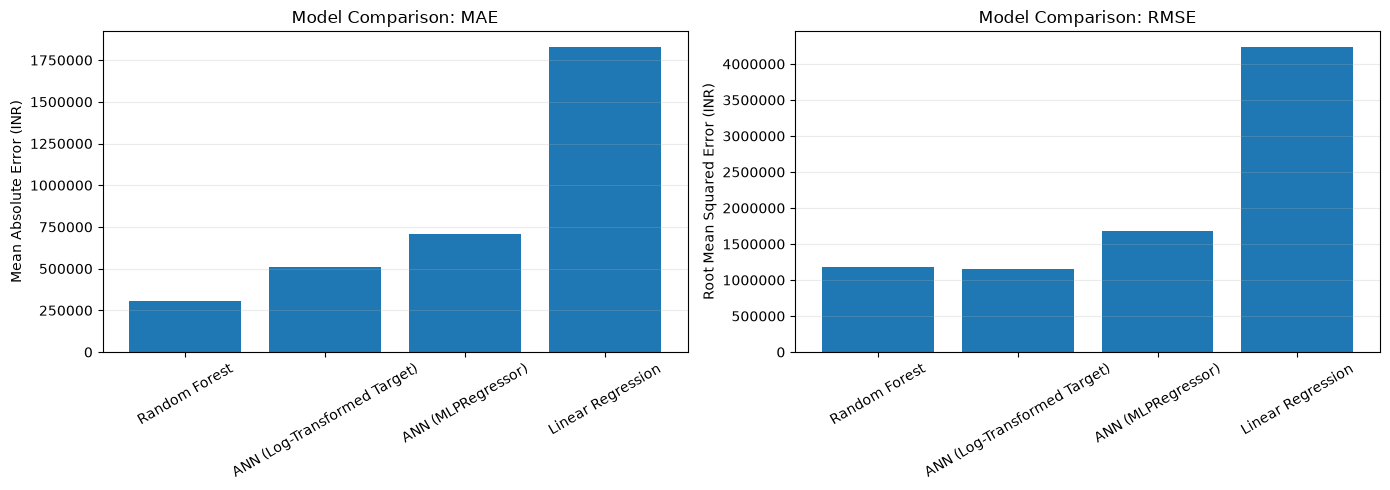

In [5]:
import matplotlib.pyplot as plt

# Create separate charts for MAE and RMSE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MAE comparison
axes[0].bar(
    results_df["model"],
    results_df["MAE"],
)
axes[0].set_title("Model Comparison: MAE")
axes[0].set_ylabel("Mean Absolute Error (INR)")
axes[0].tick_params(axis="x", rotation=30)
axes[0].ticklabel_format(style="plain", axis="y")
axes[0].grid(axis="y", alpha=0.25)

# RMSE comparison
axes[1].bar(
    results_df["model"],
    results_df["RMSE"],
)
axes[1].set_title("Model Comparison: RMSE")
axes[1].set_ylabel("Root Mean Squared Error (INR)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].ticklabel_format(style="plain", axis="y")
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()

figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "model_error_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 3. R² Score Comparison

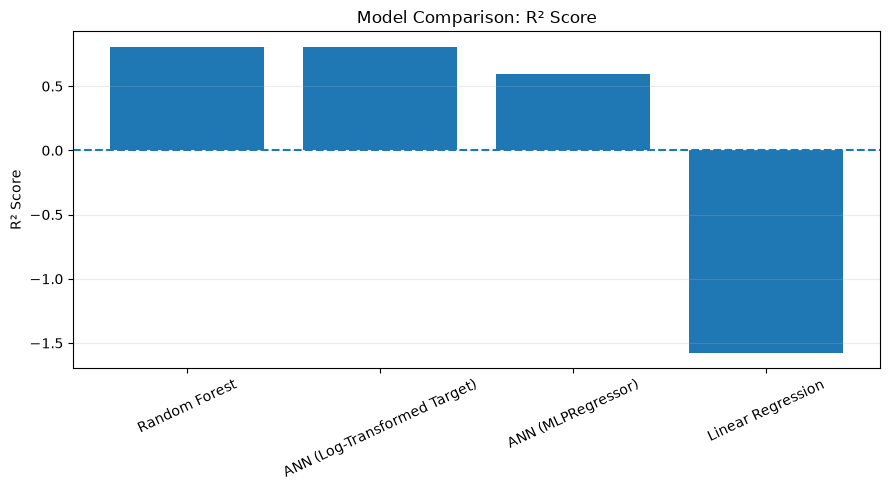

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    results_df["model"],
    results_df["R2"],
)

ax.axhline(
    y=0,
    linestyle="--",
)

ax.set_title("Model Comparison: R² Score")
ax.set_ylabel("R² Score")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "r2_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 4. Evaluation Findings

### Overall Model Comparison

Four regression models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²), using the same training and test split.

- **Linear Regression:** Performed poorly, with a negative R² score of −1.5742.
- **Original ANN:** Improved on Linear Regression, achieving an R² score of 0.5942.
- **Log-Transformed ANN:** Achieved the highest R² score (0.8079) and lowest RMSE (₹1,158,513.52) among the four models.
- **Random Forest:** Achieved the lowest MAE (₹306,199.29) and the lowest MAE across all three evaluated price segments.

### Price Segment Analysis

Random Forest achieved lower MAE than the log-transformed ANN in the budget, mid-range, and premium segments. However, prediction errors remained substantially higher for premium cars than for budget cars.

### Selected Model

Random Forest is selected as the current primary candidate because it achieved the lowest overall MAE and the lowest segment-level MAE. The log-transformed ANN remains a strong alternative because it achieved slightly better RMSE and R².

### Limitations

- The evaluation uses one train-test split, so results may vary with different splits or unseen data.
- Rare vehicle brands and models have limited representation in the training dataset.
- Premium-car predictions remain less accurate than predictions for lower-priced vehicles.
- Further validation and testing on additional data would be useful before using the model for real-world pricing decisions.

### Conclusion

The experiments show that nonlinear models outperform the Linear Regression baseline on this dataset. Random Forest provides the lowest absolute prediction error, while the log-transformed ANN performs marginally better on RMSE and R². The final model choice depends on which evaluation metric is prioritized.

### 5. Project Artifact Verification

In [7]:
# Define the expected project artifacts
expected_artifacts = {
    "Cleaned dataset": (
        PROJECT_ROOT / "data" / "processed"
        / "car_details_cleaned.csv"
    ),
    "Model comparison metrics": (
        PROJECT_ROOT / "reports" / "metrics"
        / "model_comparison.csv"
    ),
    "Random Forest pipeline": (
        PROJECT_ROOT / "models"
        / "random_forest_pipeline.joblib"
    ),
    "Original ANN plot": (
        PROJECT_ROOT / "reports" / "figures"
        / "original_ann_actual_vs_predicted.png"
    ),
    "Log-transformed ANN plot": (
        PROJECT_ROOT / "reports" / "figures"
        / "log_ann_actual_vs_predicted.png"
    ),
    "Random Forest plot": (
        PROJECT_ROOT / "reports" / "figures"
        / "random_forest_actual_vs_predicted.png"
    ),
    "MAE and RMSE comparison chart": (
        PROJECT_ROOT / "reports" / "figures"
        / "model_error_comparison.png"
    ),
    "R2 comparison chart": (
        PROJECT_ROOT / "reports" / "figures"
        / "r2_comparison.png"
    ),
}

artifact_status = pd.DataFrame([
    {
        "artifact": name,
        "exists": path.exists(),
        "path": str(path.relative_to(PROJECT_ROOT)),
    }
    for name, path in expected_artifacts.items()
])

display(artifact_status)

if artifact_status["exists"].all():
    print("\nAll expected artifacts are present.")
else:
    print("\nSome artifacts are missing. Check the table above.")

,artifact,exists,path
0,Cleaned dataset,True,data/processed/car_details_cleaned.csv
1,Model comparison metrics,True,reports/metrics/model_comparison.csv
2,Random Forest pipeline,True,models/random_forest_pipeline.joblib
3,Original ANN plot,True,reports/figures/original_ann_actual_vs_predict...
4,Log-transformed ANN plot,True,reports/figures/log_ann_actual_vs_predicted.png
5,Random Forest plot,True,reports/figures/random_forest_actual_vs_predic...
6,MAE and RMSE comparison chart,True,reports/figures/model_error_comparison.png
7,R2 comparison chart,True,reports/figures/r2_comparison.png



All expected artifacts are present.


### 6. Inspect Model Input Features

In [8]:
import joblib

MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "random_forest_pipeline.joblib"
)

loaded_model = joblib.load(MODEL_PATH)

# Retrieve the features expected by the trained pipeline
model_features = loaded_model.named_steps[
    "preprocessor"
].feature_names_in_

print("Number of input features:", len(model_features))
print("\nFeatures expected by the model:")

for feature in model_features:
    print("-", feature)

Number of input features: 19

Features expected by the model:
- make
- model
- year
- kilometer
- fuel_type
- transmission
- location
- color
- owner
- seller_type
- engine
- max_power
- max_torque
- drivetrain
- length
- width
- height
- seating_capacity
- fuel_tank_capacity


### 7. Inspect Input Options for the Prediction App

In [9]:
CLEANED_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "car_details_cleaned.csv"
)

app_data = pd.read_csv(CLEANED_DATA_PATH)

categorical_columns = [
    "make",
    "model",
    "fuel_type",
    "transmission",
    "location",
    "color",
    "owner",
    "seller_type",
    "drivetrain",
]

for column in categorical_columns:
    print(f"\n{column}: {app_data[column].nunique()} unique values")
    print(app_data[column].dropna().value_counts().head(10))


make: 33 unique values
make
Maruti Suzuki    440
Hyundai          349
Mercedes-Benz    171
Honda            158
Toyota           132
Audi             127
BMW              121
Mahindra         119
Tata              57
Volkswagen        50
Name: count, dtype: int64

model: 1050 unique values
model
X1 sDrive20d xLine                       15
Swift DZire VDI                          14
Fortuner 2.8 4x2 AT [2016-2020]          13
City V                                   13
Swift DZire VXI                          12
Swift VXi                                12
Swift VXi [2014-2017]                    12
Verna Fluidic 1.6 CRDi SX                10
A6 35 TDI Matrix                         10
5-Series 520d Luxury Line [2017-2019]    10
Name: count, dtype: int64

fuel_type: 9 unique values
fuel_type
Diesel          1049
Petrol           942
CNG               50
Electric           7
LPG                5
Hybrid             3
CNG + CNG          1
Petrol + CNG       1
Petrol + LPG       1
Name: cou

### 8. Inspect Numeric Feature Ranges

In [10]:
numeric_columns = [
    "year",
    "kilometer",
    "engine",
    "max_power",
    "max_torque",
    "length",
    "width",
    "height",
    "seating_capacity",
    "fuel_tank_capacity",
]

numeric_summary = app_data[numeric_columns].describe().T

numeric_summary = numeric_summary[
    ["count", "mean", "min", "50%", "max"]
]

display(numeric_summary.round(2))

,count,mean,min,50%,max
year,2059.0,2016.43,1988.0,2017.0,2022.0
kilometer,2059.0,54224.71,0.0,50000.0,2000000.0
engine,1979.0,1692.58,624.0,1498.0,6592.0
max_power,1979.0,129.61,35.0,116.0,660.0
max_torque,1979.0,245.85,48.0,200.0,780.0
length,1995.0,4280.86,3099.0,4370.0,5569.0
width,1995.0,1767.99,1475.0,1770.0,2220.0
height,1995.0,1591.74,1165.0,1545.0,1995.0
seating_capacity,1995.0,5.31,2.0,5.0,8.0
fuel_tank_capacity,1946.0,52.00,15.0,50.0,105.0
